# Greenhouse detection & segmentation: YOLO ➜ SAM 3

Pipeline:
1. **YOLO (Ultralytics)** predicts greenhouse bounding boxes.
2. **SAM 3** takes each predicted box as a prompt and returns a greenhouse mask.
3. **Metrics**: detection (Precision / Recall / F1 / AP50 / AP50-95 / mean IoU) for YOLO, and segmentation (instance P/R/F1/AP + pixel IoU / Dice / accuracy) for SAM 3.
4. **Plots**: ground truth vs predicted boxes and masks for each image.

**Expected dataset layout (YOLO format):**
```
dataset/
  images/  img_001.jpg ...
  labels/  img_001.txt ...   # one line per greenhouse
```
Each label line is either a polygon (`cls x1 y1 x2 y2 ... xn yn`, segmentation) or a box (`cls xc yc w h`, detection). All coordinates normalized to 0–1.
Polygon labels give both GT boxes **and** GT masks; box-only labels give GT boxes (mask metrics are then skipped for those objects).

**SAM 3 weights:** `sam3.pt` is not auto-downloaded. Request access on the SAM 3 Hugging Face page, download `sam3.pt`, and set `SAM_WEIGHTS` below. Requires `ultralytics>=8.3.237`.

In [1]:
# %pip install -q -U "ultralytics>=8.3.237" opencv-python matplotlib pandas

## 1. Configuration

In [2]:
from pathlib import Path

# ---- paths ----
# images_path = r'C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\Greenhousedataset\images'
# masks_path = r'C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\Greenhousedataset\masks'
IMAGES_DIR   = Path(r"C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\clean_yolo_dataset\images\val")      # test images
LABELS_DIR   = Path(r"C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\clean_yolo_dataset\labels\val")      # YOLO-format GT labels (polygons or boxes)
YOLO_WEIGHTS = r"C:\Users\alias\Documents\yolo26n\weights\best.pt"                   # your trained greenhouse YOLO model
SAM_WEIGHTS  = "sam3.pt"                   # SAM 3 weights (fallback: "sam2.1_b.pt")
OUT_DIR      = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)

# ---- settings ----
GREENHOUSE_CLASS_IDS = None   # e.g. [0]; None = treat every class as greenhouse
YOLO_CONF   = 0.25            # confidence threshold for YOLO boxes
YOLO_IOU    = 0.5             # NMS IoU
IMG_SIZE    = 640
MATCH_IOU   = 0.5             # IoU threshold for a true positive
DEVICE      = 0               # GPU index, or "cpu"
N_PLOTS     = 6               # how many images to visualize

## 2. Imports & helpers

In [3]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from ultralytics import YOLO, SAM

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
image_paths = sorted(p for p in IMAGES_DIR.iterdir() if p.suffix.lower() in IMG_EXTS)
print(f"Found {len(image_paths)} images")


def load_gt(label_path, h, w):
    """Read a YOLO label file -> list of dicts {box: [x1,y1,x2,y2] px, mask: HxW bool or None}."""
    objs = []
    if not label_path.exists():
        return objs
    for line in label_path.read_text().strip().splitlines():
        vals = line.split()
        if len(vals) < 5:
            continue
        cls = int(float(vals[0]))
        if GREENHOUSE_CLASS_IDS is not None and cls not in GREENHOUSE_CLASS_IDS:
            continue
        coords = np.array(vals[1:], dtype=float)
        if len(coords) == 4:                       # bbox: xc yc bw bh
            xc, yc, bw, bh = coords * [w, h, w, h]
            box = [xc - bw / 2, yc - bh / 2, xc + bw / 2, yc + bh / 2]
            objs.append({"box": box, "mask": None})
        else:                                      # polygon
            poly = coords.reshape(-1, 2) * [w, h]
            mask = np.zeros((h, w), np.uint8)
            cv2.fillPoly(mask, [poly.round().astype(np.int32)], 1)
            box = [poly[:, 0].min(), poly[:, 1].min(), poly[:, 0].max(), poly[:, 1].max()]
            objs.append({"box": box, "mask": mask.astype(bool)})
    return objs


def box_iou(a, b):
    """IoU matrix between boxes a (N,4) and b (M,4), xyxy."""
    a, b = np.asarray(a, float).reshape(-1, 4), np.asarray(b, float).reshape(-1, 4)
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)


def mask_iou(a, b):
    """IoU matrix between mask lists a (N,H,W) and b (M,H,W)."""
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    A = np.stack(a).reshape(len(a), -1).astype(np.float32)
    B = np.stack(b).reshape(len(b), -1).astype(np.float32)
    inter = A @ B.T
    union = A.sum(1)[:, None] + B.sum(1)[None, :] - inter
    return inter / (union + 1e-9)


def greedy_match(iou, scores, thr):
    """Match predictions (rows, sorted by score) to GT (cols). Returns tp flags and matched IoUs."""
    order = np.argsort(-np.asarray(scores))
    used = set(); tp = np.zeros(iou.shape[0], bool); matched = np.zeros(iou.shape[0])
    for i in order:
        if iou.shape[1] == 0:
            break
        cand = [(iou[i, j], j) for j in range(iou.shape[1]) if j not in used and iou[i, j] >= thr]
        if cand:
            v, j = max(cand)
            used.add(j); tp[i] = True; matched[i] = v
    return tp, matched


def average_precision(records, n_gt):
    """All-point interpolated AP. records = list of (score, is_tp)."""
    if n_gt == 0 or not records:
        return 0.0
    rec = sorted(records, key=lambda r: -r[0])
    tps = np.cumsum([r[1] for r in rec]); fps = np.cumsum([not r[1] for r in rec])
    recall = tps / n_gt; precision = tps / np.maximum(tps + fps, 1e-9)
    mrec = np.concatenate([[0], recall, [1]]); mpre = np.concatenate([[1], precision, [0]])
    mpre = np.flip(np.maximum.accumulate(np.flip(mpre)))
    idx = np.where(mrec[1:] != mrec[:-1])[0]
    return float(np.sum((mrec[idx + 1] - mrec[idx]) * mpre[idx + 1]))

Found 21184 images


## 3. Load models

In [4]:
yolo = YOLO(YOLO_WEIGHTS)
sam  = SAM(SAM_WEIGHTS)   # SAM 3 with box (visual) prompts: one mask per box
print("YOLO classes:", yolo.names)

YOLO classes: {0: 'greenhouse'}


## 4. Run the pipeline: YOLO boxes ➜ SAM 3 masks
For every image, YOLO predicts boxes; those boxes are passed to SAM 3 as prompts, so mask *i* belongs to box *i* and inherits its confidence.

In [5]:
from tqdm.auto import tqdm

results = []   # one dict per image
for img_path in tqdm(image_paths[:5]):
    img = cv2.imread(str(img_path)); h, w = img.shape[:2]
    gt = load_gt(LABELS_DIR / f"{img_path.stem}.txt", h, w)

    # --- 1) YOLO detection ---
    det = yolo.predict(img, conf=YOLO_CONF, iou=YOLO_IOU, imgsz=IMG_SIZE, device=DEVICE, verbose=False)[0]
    boxes  = det.boxes.xyxy.cpu().numpy()
    scores = det.boxes.conf.cpu().numpy()
    clss   = det.boxes.cls.cpu().numpy().astype(int)
    if GREENHOUSE_CLASS_IDS is not None:
        keep = np.isin(clss, GREENHOUSE_CLASS_IDS)
        boxes, scores = boxes[keep], scores[keep]

    # --- 2) SAM 3 segmentation prompted by YOLO boxes ---
    pred_masks = []
    if len(boxes):
        seg = sam.predict(img, bboxes=boxes.tolist(), device=DEVICE, verbose=False)[0]
        if seg.masks is not None:
            m = seg.masks.data.cpu().numpy()
            if m.shape[1:] != (h, w):   # safety: resize to image size
                m = np.stack([cv2.resize(x.astype(np.uint8), (w, h), interpolation=cv2.INTER_NEAREST) for x in m])
            pred_masks = [x.astype(bool) for x in m]
        # keep boxes and masks aligned (one mask per box)
        n = min(len(pred_masks), len(boxes))
        boxes, scores, pred_masks = boxes[:n], scores[:n], pred_masks[:n]

    results.append({
        "path": img_path, "h": h, "w": w,
        "gt_boxes": np.array([o["box"] for o in gt]).reshape(-1, 4),
        "gt_masks": [o["mask"] for o in gt],
        "pred_boxes": boxes, "pred_scores": scores, "pred_masks": pred_masks,
    })

print("Total GT objects:", sum(len(r["gt_boxes"]) for r in results))
print("Total predictions:", sum(len(r["pred_boxes"]) for r in results))

  0%|          | 0/5 [00:00<?, ?it/s]

WARNING imgsz=[1024] must be multiple of max stride 14, updating to [1036]
WARNING imgsz=[1024] must be multiple of max stride 14, updating to [1036]
WARNING imgsz=[1024] must be multiple of max stride 14, updating to [1036]
WARNING imgsz=[1024] must be multiple of max stride 14, updating to [1036]
Total GT objects: 27
Total predictions: 19


## 5. Metrics
**Detection (YOLO)** – box IoU matching: Precision, Recall, F1 at IoU ≥ `MATCH_IOU`, AP50, AP50-95, mean IoU of matched boxes.

**Segmentation (SAM 3)** – instance level (mask IoU matching): Precision, Recall, F1, AP50, AP50-95, mean mask IoU; pixel level (all greenhouse pixels per image): IoU, Dice, Precision, Recall, Accuracy.

In [6]:
IOU_THRS = np.arange(0.5, 0.96, 0.05)

def instance_metrics(kind):
    """kind = 'box' or 'mask'."""
    recs = {t: [] for t in IOU_THRS}; n_gt = 0; tp50 = fp50 = 0; matched_ious = []
    for r in results:
        if kind == "box":
            gt_items, pr_items = r["gt_boxes"], r["pred_boxes"]
            iou = box_iou(pr_items, gt_items)
        else:
            gt_items = [m for m in r["gt_masks"] if m is not None]
            pr_items = r["pred_masks"]
            iou = mask_iou(pr_items, gt_items)
        n_gt += len(gt_items)
        for t in IOU_THRS:
            tp, m = greedy_match(iou, r["pred_scores"][:len(pr_items)], t)
            recs[t] += list(zip(r["pred_scores"][:len(pr_items)], tp))
            if np.isclose(t, MATCH_IOU):
                tp50 += tp.sum(); fp50 += (~tp).sum(); matched_ious += list(m[tp])
    P = tp50 / max(tp50 + fp50, 1); R = tp50 / max(n_gt, 1)
    aps = [average_precision(recs[t], n_gt) for t in IOU_THRS]
    return {
        "GT objects": n_gt, "Predictions": int(tp50 + fp50), "TP": int(tp50), "FP": int(fp50), "FN": int(n_gt - tp50),
        "Precision": P, "Recall": R, "F1": 2 * P * R / max(P + R, 1e-9),
        "AP50": aps[0], "AP50-95": float(np.mean(aps)),
        "Mean IoU (matched)": float(np.mean(matched_ious)) if matched_ious else 0.0,
    }

def pixel_metrics():
    TP = FP = FN = TN = 0
    for r in results:
        if not any(m is not None for m in r["gt_masks"]):
            continue
        gt = np.zeros((r["h"], r["w"]), bool)
        for m in r["gt_masks"]:
            if m is not None: gt |= m
        pr = np.zeros_like(gt)
        for m in r["pred_masks"]: pr |= m
        TP += (gt & pr).sum(); FP += (~gt & pr).sum(); FN += (gt & ~pr).sum(); TN += (~gt & ~pr).sum()
    return {
        "Pixel IoU": TP / max(TP + FP + FN, 1), "Dice / F1": 2 * TP / max(2 * TP + FP + FN, 1),
        "Pixel Precision": TP / max(TP + FP, 1), "Pixel Recall": TP / max(TP + FN, 1),
        "Pixel Accuracy": (TP + TN) / max(TP + FP + FN + TN, 1),
    }

det_metrics  = instance_metrics("box")
seg_metrics  = instance_metrics("mask")
pix_metrics  = pixel_metrics()

summary = pd.DataFrame({"YOLO (boxes)": det_metrics, "SAM 3 (masks)": seg_metrics})
display(summary.style.format("{:.4f}", subset=pd.IndexSlice[["Precision","Recall","F1","AP50","AP50-95","Mean IoU (matched)"], :]))
display(pd.Series(pix_metrics, name="SAM 3 pixel-level").to_frame().style.format("{:.4f}"))

summary.to_csv(OUT_DIR / "instance_metrics.csv")
pd.Series(pix_metrics).to_csv(OUT_DIR / "pixel_metrics.csv")

,YOLO (boxes),SAM 3 (masks)
GT objects,27.000000,0.000000
Predictions,19.000000,19.000000
TP,5.000000,0.000000
FP,14.000000,19.000000
FN,22.000000,0.000000
Precision,0.2632,0.0000
Recall,0.1852,0.0000
F1,0.2174,0.0000
AP50,0.1083,0.0000
AP50-95,0.0841,0.0000


,SAM 3 pixel-level
Pixel IoU,0.0000
Dice / F1,0.0000
Pixel Precision,0.0000
Pixel Recall,0.0000
Pixel Accuracy,0.0000


### Per-image metrics

In [7]:
rows = []
for r in results:
    biou = box_iou(r["pred_boxes"], r["gt_boxes"])
    tp_b, _ = greedy_match(biou, r["pred_scores"], MATCH_IOU)
    gtm = [m for m in r["gt_masks"] if m is not None]
    miou = mask_iou(r["pred_masks"], gtm)
    tp_m, _ = greedy_match(miou, r["pred_scores"][:len(r["pred_masks"])], MATCH_IOU)
    gt_u = np.zeros((r["h"], r["w"]), bool); pr_u = np.zeros_like(gt_u)
    for m in gtm: gt_u |= m
    for m in r["pred_masks"]: pr_u |= m
    union = (gt_u | pr_u).sum()
    rows.append({
        "image": r["path"].name, "GT": len(r["gt_boxes"]), "Pred": len(r["pred_boxes"]),
        "Box TP": int(tp_b.sum()), "Mask TP": int(tp_m.sum()),
        "Pixel IoU": (gt_u & pr_u).sum() / union if union else np.nan,
    })
per_image = pd.DataFrame(rows).sort_values("Pixel IoU")
per_image.to_csv(OUT_DIR / "per_image_metrics.csv", index=False)
per_image.head(20)

,image,GT,Pred,Box TP,Mask TP,Pixel IoU
1,102.png,4,5,4,0,0.0
2,103.png,20,4,0,0,0.0
3,109.png,1,4,1,0,0.0
4,11.png,1,6,0,0,0.0
0,10.png,1,0,0,0,NaN


### Metrics chart

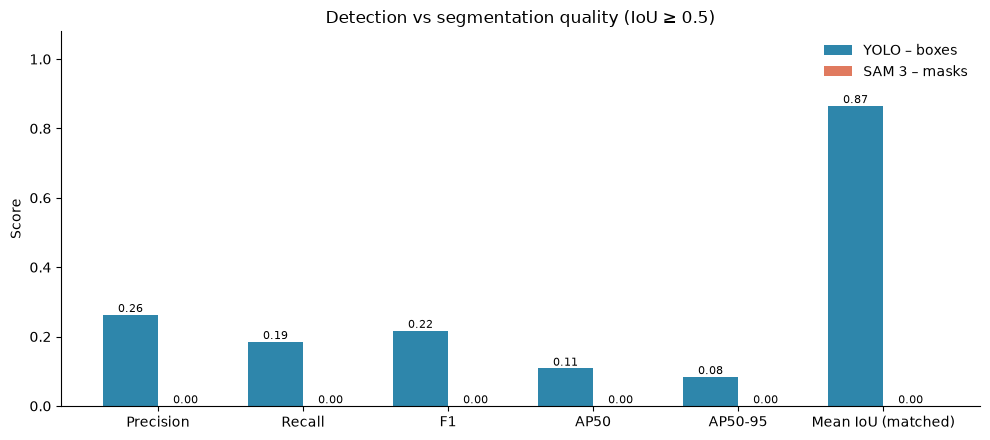

In [8]:
keys = ["Precision", "Recall", "F1", "AP50", "AP50-95", "Mean IoU (matched)"]
x = np.arange(len(keys)); bw = 0.38
fig, ax = plt.subplots(figsize=(10, 4.5))
b1 = ax.bar(x - bw/2, [det_metrics[k] for k in keys], bw, label="YOLO – boxes", color="#2E86AB")
b2 = ax.bar(x + bw/2, [seg_metrics[k] for k in keys], bw, label="SAM 3 – masks", color="#E07A5F")
ax.bar_label(b1, fmt="%.2f", fontsize=8); ax.bar_label(b2, fmt="%.2f", fontsize=8)
ax.set_xticks(x, keys); ax.set_ylim(0, 1.08); ax.set_ylabel("Score")
ax.set_title(f"Detection vs segmentation quality (IoU ≥ {MATCH_IOU})")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(OUT_DIR / "metrics_bar.png", dpi=150); plt.show()

## 6. Visualize: ground truth vs prediction
Left: image + **GT** (green boxes & masks). Middle: image + **prediction** (red YOLO boxes with confidence, SAM 3 masks). Right: error map — green = TP pixels, red = FP pixels, blue = FN pixels.

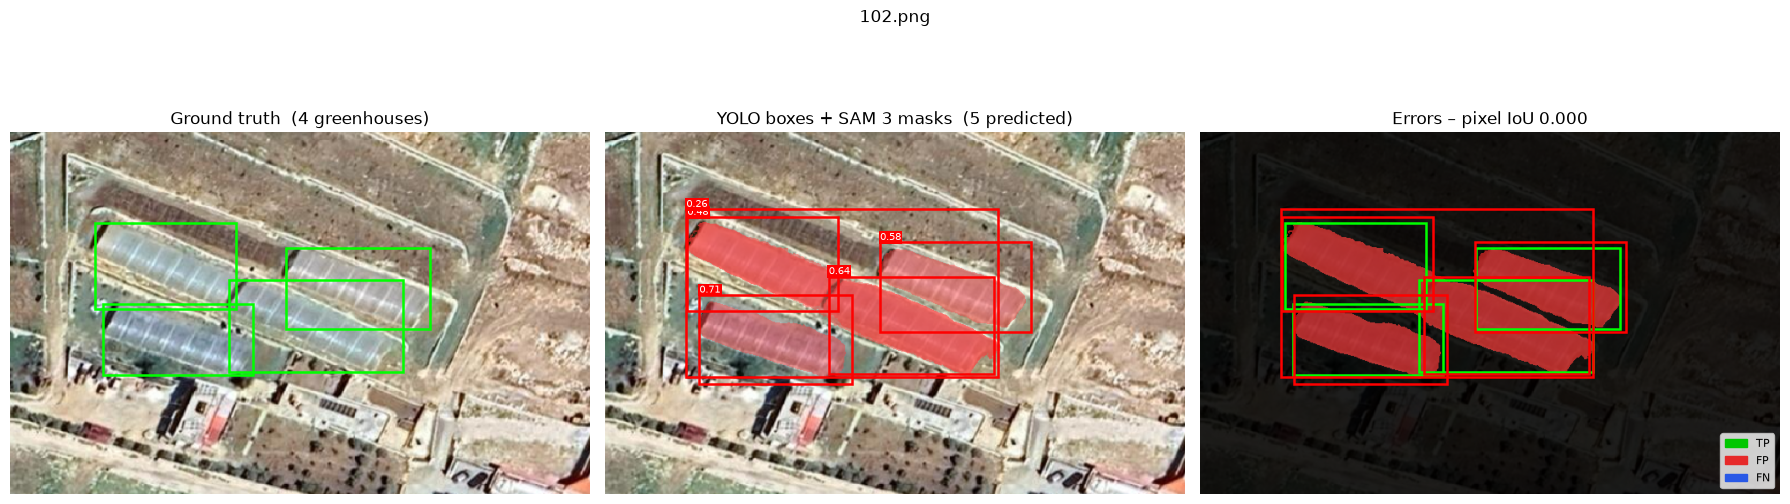

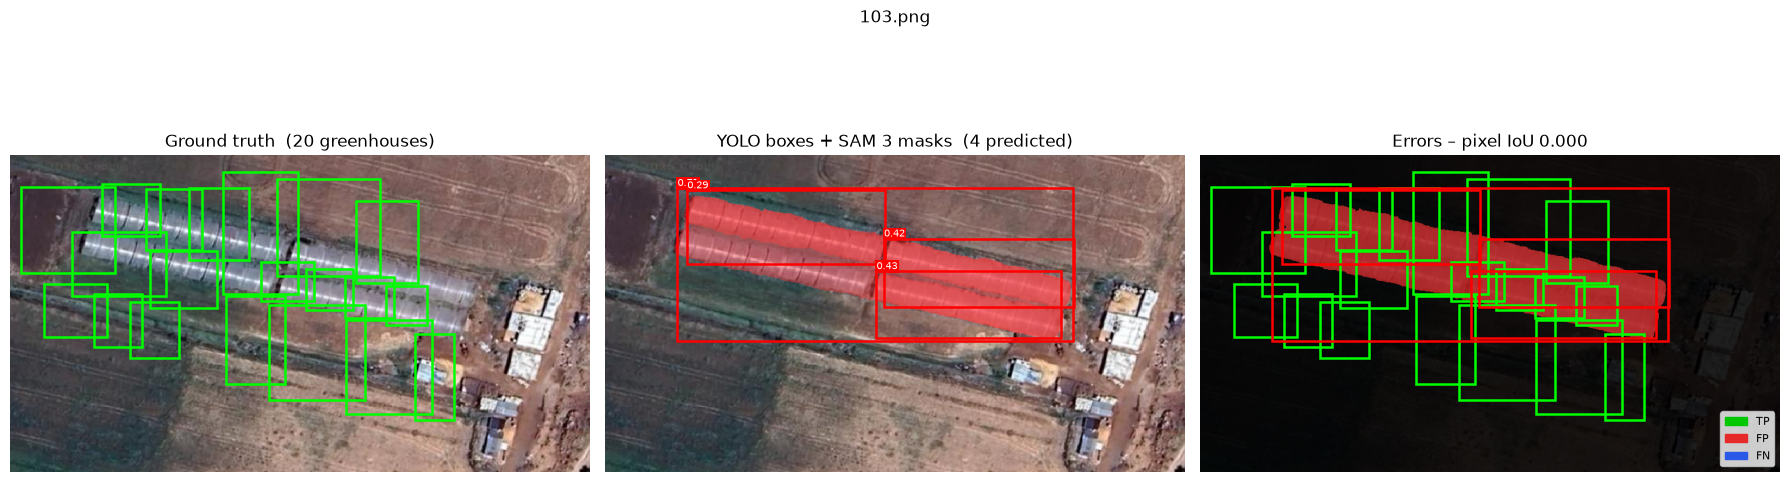

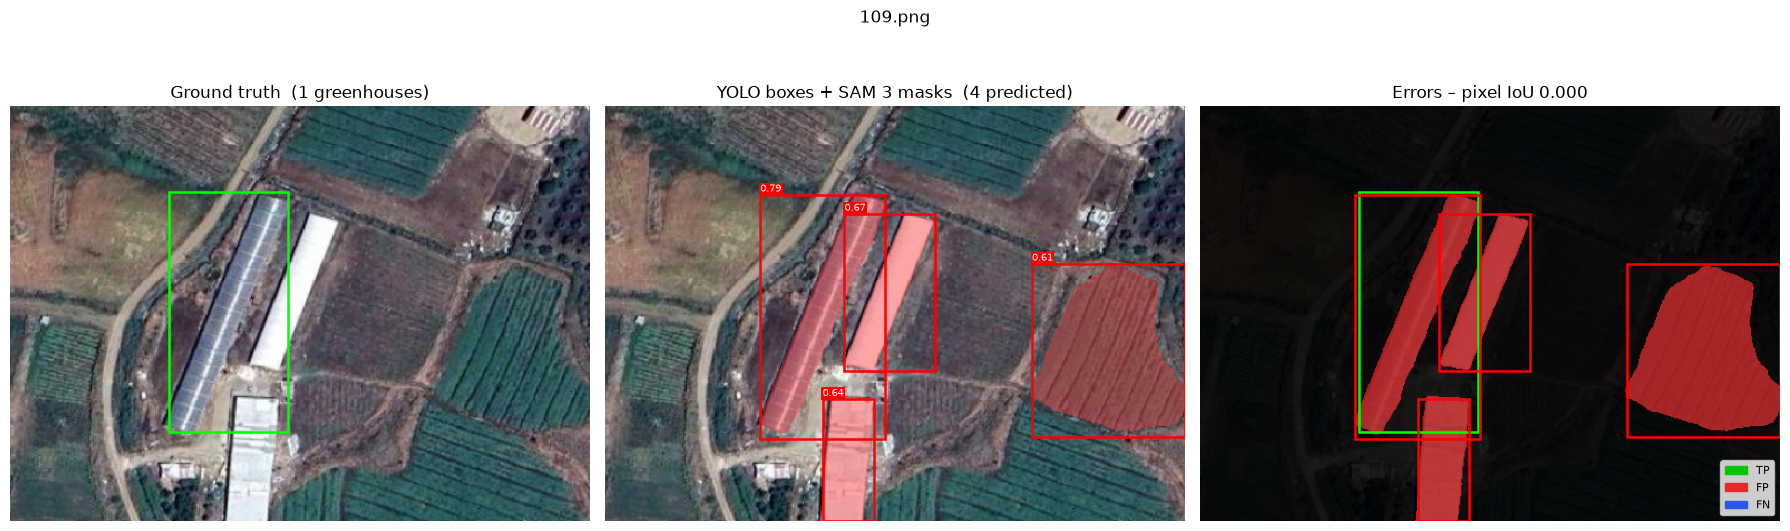

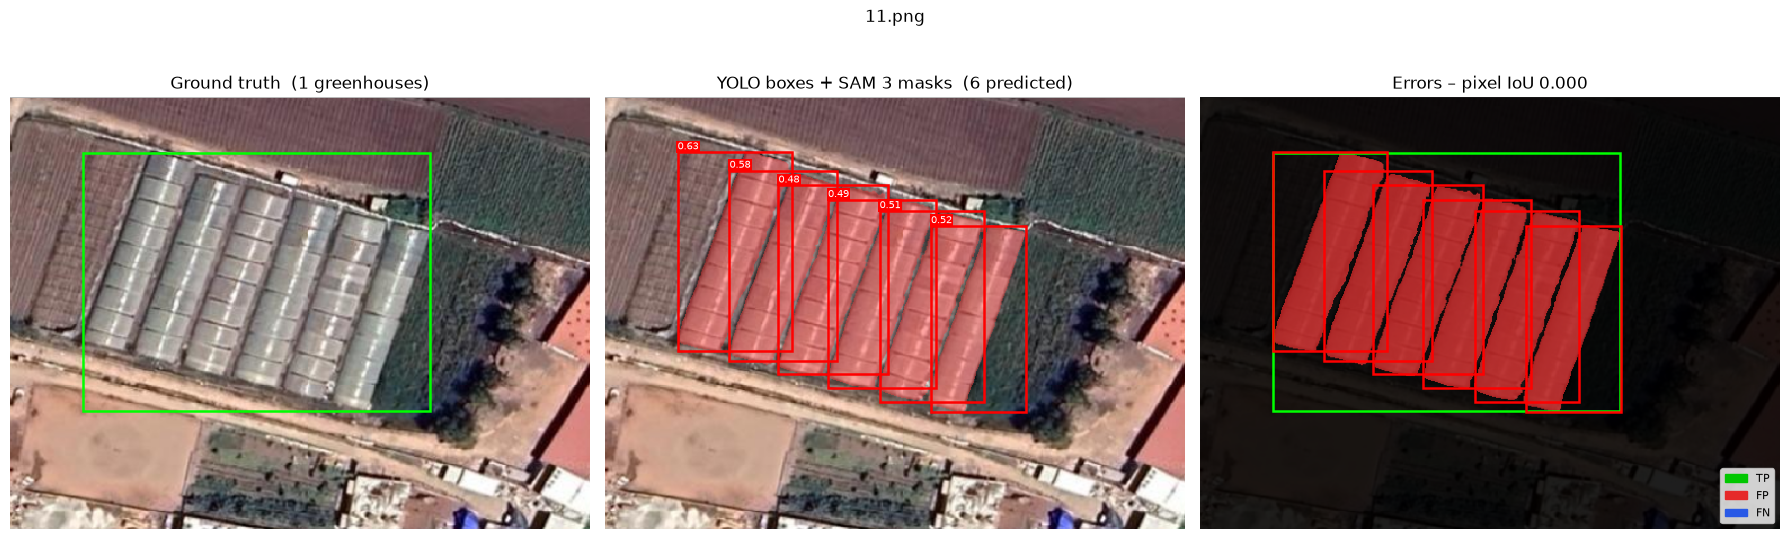

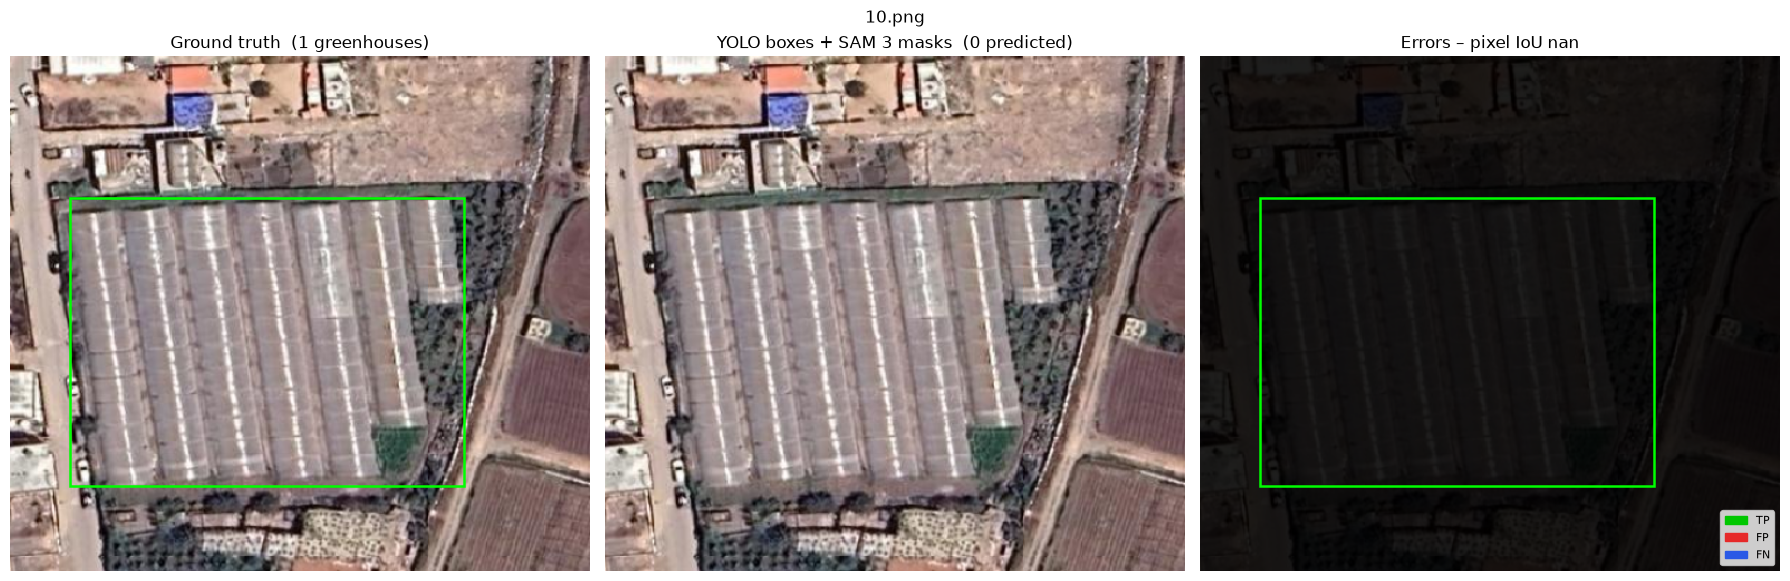

In [9]:
def overlay(img_rgb, masks, color, alpha=0.45):
    out = img_rgb.astype(np.float32).copy()
    for m in masks:
        if m is None: continue
        out[m] = out[m] * (1 - alpha) + np.array(color) * alpha
    return out.astype(np.uint8)

def draw_boxes(ax, boxes, color, scores=None):
    for i, (x1, y1, x2, y2) in enumerate(boxes):
        ax.add_patch(mpatches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec=color, lw=1.8))
        if scores is not None:
            ax.text(x1, y1 - 3, f"{scores[i]:.2f}", color="white", fontsize=7,
                    bbox=dict(fc=color, ec="none", pad=1))

def plot_result(r):
    img = cv2.cvtColor(cv2.imread(str(r["path"])), cv2.COLOR_BGR2RGB)
    gt_u = np.zeros(img.shape[:2], bool); pr_u = np.zeros_like(gt_u)
    for m in r["gt_masks"]:
        if m is not None: gt_u |= m
    for m in r["pred_masks"]: pr_u |= m
    err = np.zeros((*gt_u.shape, 3), np.uint8)
    err[gt_u & pr_u] = (0, 200, 0); err[~gt_u & pr_u] = (230, 40, 40); err[gt_u & ~pr_u] = (40, 90, 230)
    union = (gt_u | pr_u).sum(); piou = (gt_u & pr_u).sum() / union if union else float("nan")

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    axes[0].imshow(overlay(img, r["gt_masks"], (0, 255, 0)));  draw_boxes(axes[0], r["gt_boxes"], "lime")
    axes[0].set_title(f"Ground truth  ({len(r['gt_boxes'])} greenhouses)")
    axes[1].imshow(overlay(img, r["pred_masks"], (255, 60, 60))); draw_boxes(axes[1], r["pred_boxes"], "red", r["pred_scores"])
    axes[1].set_title(f"YOLO boxes + SAM 3 masks  ({len(r['pred_boxes'])} predicted)")
    axes[2].imshow((img * 0.4).astype(np.uint8)); axes[2].imshow(err, alpha=0.7)
    draw_boxes(axes[2], r["gt_boxes"], "lime"); draw_boxes(axes[2], r["pred_boxes"], "red")
    axes[2].set_title(f"Errors – pixel IoU {piou:.3f}")
    axes[2].legend(handles=[mpatches.Patch(color=(0, .78, 0), label="TP"),
                            mpatches.Patch(color=(.9, .16, .16), label="FP"),
                            mpatches.Patch(color=(.16, .35, .9), label="FN")], loc="lower right", fontsize=8)
    for a in axes: a.axis("off")
    fig.suptitle(r["path"].name, fontsize=12)
    plt.tight_layout(); plt.savefig(OUT_DIR / f"viz_{r['path'].stem}.png", dpi=130); plt.show()

# show worst and best images by pixel IoU
order = per_image["image"].tolist()
by_name = {r["path"].name: r for r in results}
picks = order[: N_PLOTS // 2] + order[-(N_PLOTS - N_PLOTS // 2):]
for name in dict.fromkeys(picks):
    plot_result(by_name[name])

## Notes
- **Change `GREENHOUSE_CLASS_IDS`** if your YOLO model has more than one class.
- If you don't have `sam3.pt` yet, set `SAM_WEIGHTS = "sam2.1_b.pt"` to run the same pipeline with SAM 2.1 (auto-downloads) and compare.
- SAM masks inherit YOLO confidences, so SAM 3's AP also depends on YOLO's ranking; a missed YOLO box can never be recovered by SAM (FN in both).
- All metrics, per-image tables and figures are saved to `outputs/`.